In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sym

# Test the gradient descent algorithm for the following function

f(x) = cos(2*pi*x)+x**2

On the interval

x {-2,2}

Also, execute the algorithm with a starting value of x = 0

## Gradient descent 1D

In [2]:
# Set function context
x = sym.symbols('x')

# Define function
fx = sym.cos(2*sym.pi*x)+x**2

fx_numpy = sym.lambdify(x, fx, modules='numpy')

print('fx')
display(fx)

# Compute derivative

dx = sym.diff(fx)
dx_numpy = sym.lambdify(x,dx,modules='numpy')
print('dx')
display(dx)

fx


x**2 + cos(2*pi*x)

dx


2*x - 2*pi*sin(2*pi*x)

In [3]:
# Define global variables
# Number of values in the set

n = 100
topLimit = 2
botLimit = -2

# x value set

xset = np.linspace(botLimit,topLimit,n)

print(xset)

[-2.         -1.95959596 -1.91919192 -1.87878788 -1.83838384 -1.7979798
 -1.75757576 -1.71717172 -1.67676768 -1.63636364 -1.5959596  -1.55555556
 -1.51515152 -1.47474747 -1.43434343 -1.39393939 -1.35353535 -1.31313131
 -1.27272727 -1.23232323 -1.19191919 -1.15151515 -1.11111111 -1.07070707
 -1.03030303 -0.98989899 -0.94949495 -0.90909091 -0.86868687 -0.82828283
 -0.78787879 -0.74747475 -0.70707071 -0.66666667 -0.62626263 -0.58585859
 -0.54545455 -0.50505051 -0.46464646 -0.42424242 -0.38383838 -0.34343434
 -0.3030303  -0.26262626 -0.22222222 -0.18181818 -0.14141414 -0.1010101
 -0.06060606 -0.02020202  0.02020202  0.06060606  0.1010101   0.14141414
  0.18181818  0.22222222  0.26262626  0.3030303   0.34343434  0.38383838
  0.42424242  0.46464646  0.50505051  0.54545455  0.58585859  0.62626263
  0.66666667  0.70707071  0.74747475  0.78787879  0.82828283  0.86868687
  0.90909091  0.94949495  0.98989899  1.03030303  1.07070707  1.11111111
  1.15151515  1.19191919  1.23232323  1.27272727  1.3

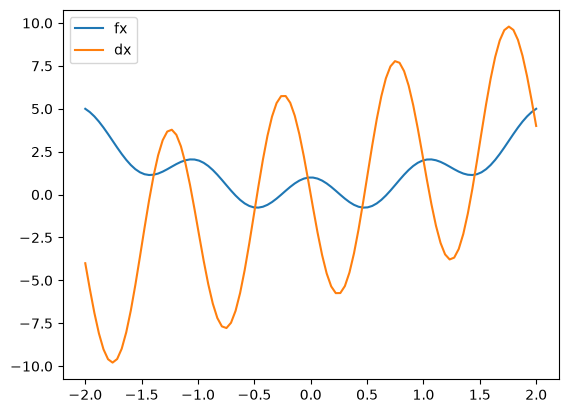

In [4]:
# Create starting plto for the function fx

plt.plot(xset,fx_numpy(xset))
plt.plot(xset,dx_numpy(xset))
plt.legend(['fx','dx'])
plt.show()

In [74]:
# Gradient descent algorithm

def gd_train(data,training_epochs = 100, learning_rate=0.01, localmin = None):
    print("Training")
    localmin = np.random.choice(data,1) if localmin is None else localmin
    print("Localmin selected:", localmin)
    modelparams = np.zeros((training_epochs,2))
    
    for i in range(training_epochs):
        # grad = dx.subs(x, localmin[0]) # Way to slow
        grad = dx_numpy(localmin[0])
        localmin = localmin - learning_rate*grad
        modelparams[i,0] = localmin[0]
        modelparams[i,1] = grad

    print("Final localmin:", localmin)
        
    print("Ploting")
    
     # plot the computed localmin
    fig,ax= plt.subplots(2,2,figsize=(12,8))
    
    for i in range(2):
        ax[0][i].plot(modelparams[:,i],'o-')
        ax[0][i].set_xlabel('iteration')
        ax[0][i].set_title(f'Final estimated minimum {localmin[0]:0.5f}')
    
    ax[0][0].set_ylabel('Local minimum')
    ax[0][1].set_ylabel('Derivative')

    ax[1][0].plot(xset,fx_numpy(xset),'g')
    ax[1][0].plot(localmin,fx_numpy(localmin),'ro')
    ax[1][0].plot(xset,dx_numpy(xset),'y')   
    ax[1][0].plot(localmin,dx_numpy(localmin),'ro')   
    
    plt.show()


Training
Localmin selected: [0.82828283]
Final localmin: [0.47580245]
Ploting


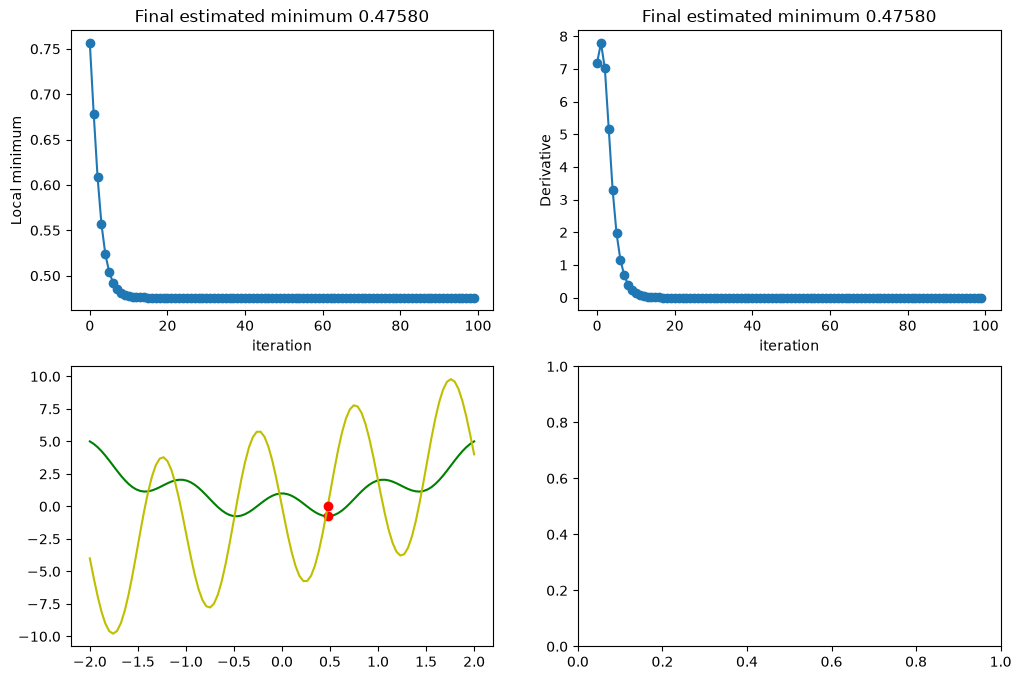

In [83]:
# Execute training

gd_train(xset)

Training
Localmin selected: [0]
Final localmin: [0.]
Ploting


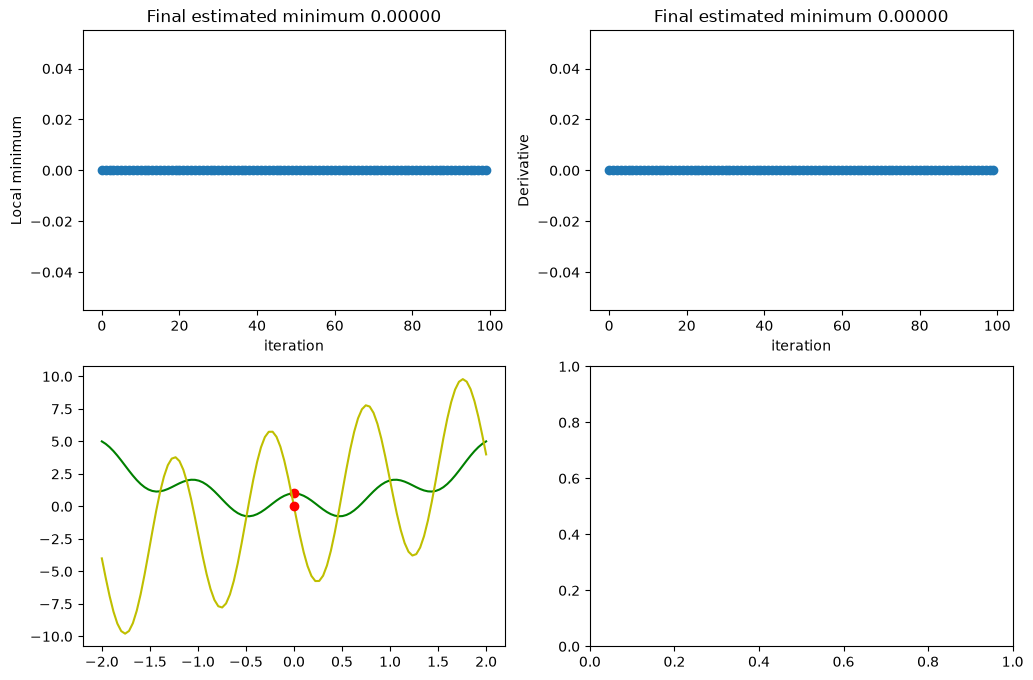

In [85]:
# Force localminima to zero
gd_train(xset,100,.01,[0])